In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa debe elegir **una sola** de tres inversiones excluyentes (flujos de caja en k€ al final de cada año; el año 0 es la inversión). A y B duran 6 años; C dura 3 y puede repetirse indefinidamente en las mismas condiciones. La tasa de descuento es del 8%.

In [4]:
pregunta_1 = "1. Calcule el VAN, la TIR y el payback de A y de B. ¿Qué proyecto prefiere cada criterio?  "
pregunta_2 = "2. Explique por qué VAN y TIR pueden discrepar entre proyectos excluyentes. Calcule la tasa de Fisher (la que iguala los VAN) a partir de los flujos diferenciales A − B y dibuje los dos perfiles de VAN.  "
pregunta_3 = "3. ¿Para qué tasas de descuento se prefiere A y para cuáles B? ¿Cuál es la decisión correcta a la tasa dada y por qué manda el VAN?  "
pregunta_4 = "4. C tiene menor vida. Compare C con la mejor de A y B mediante la anualidad equivalente (o la cadena de repeticiones). ¿Cambia la decisión?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el VAN, la TIR y el payback de A y de B. ¿Qué proyecto prefiere cada criterio?  

2. Explique por qué VAN y TIR pueden discrepar entre proyectos excluyentes. Calcule la tasa de Fisher (la que iguala los VAN) a partir de los flujos diferenciales A − B y dibuje los dos perfiles de VAN.  

3. ¿Para qué tasas de descuento se prefiere A y para cuáles B? ¿Cuál es la decisión correcta a la tasa dada y por qué manda el VAN?  

4. C tiene menor vida. Compare C con la mejor de A y B mediante la anualidad equivalente (o la cadena de repeticiones). ¿Cambia la decisión?  

In [5]:
#| tbl-cap: "Flujos de caja de las alternativas (k€)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  year, A   , B   , C   
    (0   , -440, -440, -260),
    (1   , 60  , 165 , 105 ),
    (2   , 80  , 140 , 105 ),
    (3   , 105 , 120 , 105 ),
    (4   , 135 , 105 , 0   ),
    (5   , 175 , 90  , 0   ),
    (6   , 230 , 80  , 0   ),
], columns=['year', 'A', 'B', 'C']).set_index('year')
datos_enunciado

,A,B,C
year,,,
0,-440,-440,-260
1,60,165,105
2,80,140,105
3,105,120,105
4,135,105,0
5,175,90,0
6,230,80,0


# Resolución

In [6]:
def van(flujos, k):
    '''Valor actual neto de una lista de flujos (el primero en t = 0) a la tasa k.'''
    return float(sum(f / (1 + k) ** t for t, f in enumerate(flujos)))

def tir(flujos):
    '''Tasa que anula el VAN (por bisección entre −99 % y 1000 %).'''
    from scipy.optimize import brentq
    return float(brentq(lambda k: van(flujos, k), -0.99, 10.0))

def tabla_descuento(flujos, k):
    '''Año, flujo, factor de descuento, valor actual y valores acumulados (simple y descontado).'''
    t = pd.DataFrame({'flujo': list(flujos)}, index=pd.Index(range(len(flujos)), name='año'))
    t['(1 + k)^-t'] = [(1 + k) ** -i for i in t.index]
    t['valor actual'] = t['flujo'] * t['(1 + k)^-t']
    t['acumulado'] = t['flujo'].cumsum()
    t['acumulado descontado'] = t['valor actual'].cumsum()
    return t

def payback(flujos, k=None):
    '''Periodo de recuperación (años, con interpolación lineal dentro del año); descontado si se da k.'''
    acum = 0.0
    for t, f in enumerate(flujos):
        v = f if k is None else f / (1 + k) ** t
        if t > 0 and acum < 0 <= acum + v:
            return float(t - 1 + (-acum) / v)
        acum += v
    return float('inf')

def anualidad_equivalente(VAN, k, n):
    '''Anualidad constante durante n años cuyo valor actual es VAN.'''
    return float(VAN * k / (1 - (1 + k) ** -n))

In [7]:
k, n, m = 0.08, 6, 3
A, B = datos_enunciado['A'].tolist(), datos_enunciado['B'].tolist()
C = datos_enunciado['C'].tolist()[:m + 1]

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Calcule el VAN, la TIR y el payback de A y de B. ¿Qué proyecto prefiere cada criterio?  

In [9]:
#| tbl-cap: "Criterios para A y B"
#| label: tbl-criterios
criterios = pd.DataFrame({p: {'VAN (k€)': van(f, k), 'TIR': tir(f), 'payback (años)': payback(f), 'payback descontado': payback(f, k)}
                          for p, f in (('A', A), ('B', B))}).T
criterios.round(3)

,VAN (k€),TIR,payback (años),payback descontado
A,130.765,0.154,4.343,5.098
B,116.909,0.176,3.143,3.932


In [10]:
Markdown(f'El VAN prefiere {criterios["VAN (k€)"].idxmax()} y la TIR prefiere {criterios["TIR"].idxmax()}: los criterios discrepan.')

El VAN prefiere A y la TIR prefiere B: los criterios discrepan.

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Explique por qué VAN y TIR pueden discrepar entre proyectos excluyentes. Calcule la tasa de Fisher (la que iguala los VAN) a partir de los flujos diferenciales A − B y dibuje los dos perfiles de VAN.  

La TIR es una medida *relativa* (rentabilidad por euro y año) y supone la reinversión de los flujos a la propia TIR; el VAN es *absoluto* (euros de valor creado a la tasa de descuento). Cuando los proyectos tienen distinto perfil temporal (A cobra tarde, B cobra pronto) sus perfiles de VAN se cruzan: a la tasa de Fisher ambos valen lo mismo.

In [12]:
diferencial = [a - b for a, b in zip(A, B)]
fisher = tir(diferencial)
display(pd.DataFrame({'A': A, 'B': B, 'A − B': diferencial}, index=pd.Index(range(n + 1), name='año')).T)
Markdown(f'Tasa de Fisher: TIR de los flujos A − B = {fisher:.2%}; a esa tasa VAN_A = {van(A, fisher):.1f} = VAN_B = {van(B, fisher):.1f}.')

año,0,1,2,3,4,5,6
A,-440,60,80,105,135,175,230
B,-440,165,140,120,105,90,80
A − B,0,-105,-60,-15,30,85,150


Tasa de Fisher: TIR de los flujos A − B = 10.29%; a esa tasa VAN_A = 84.7 = VAN_B = 84.7.

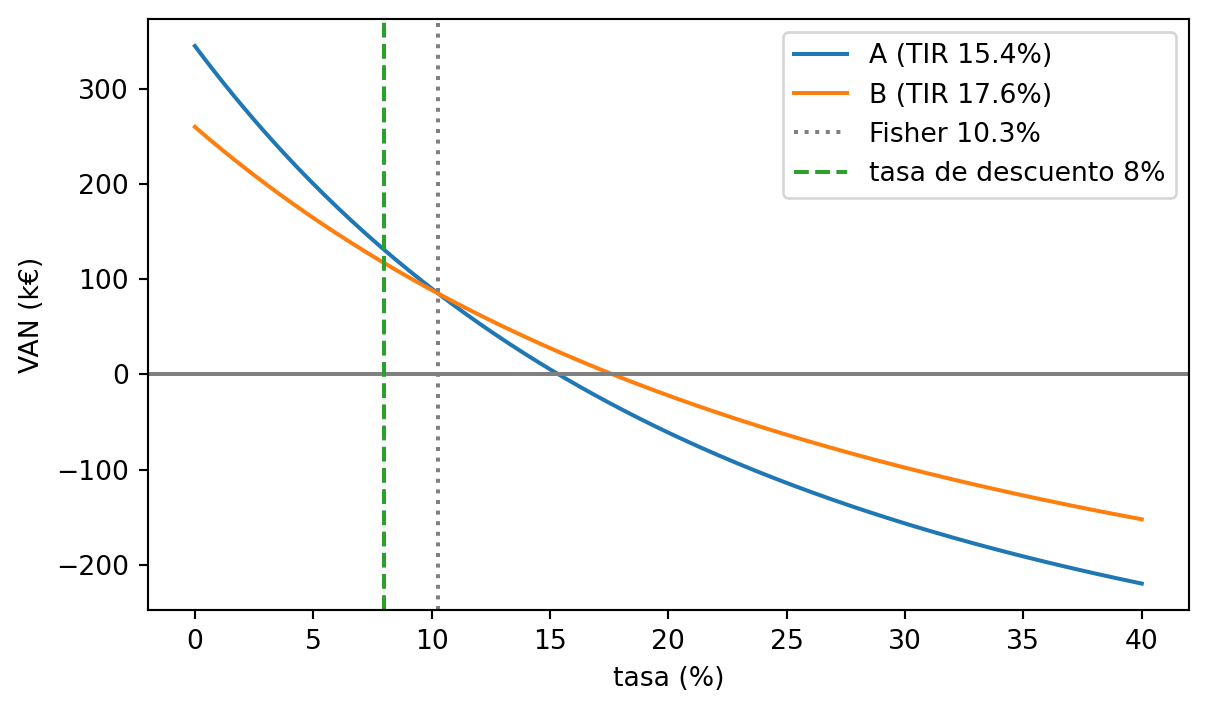

In [13]:
#| fig-cap: "Perfiles de VAN de A y B"
#| label: fig-perfiles
from matplotlib import pyplot as plt
ks = np.linspace(0, 0.4, 200)
fig, ax = plt.subplots(figsize=(7, 4))
for nombre, f in (('A', A), ('B', B)):
    ax.plot(ks * 100, [van(f, x) for x in ks], label=f'{nombre} (TIR {tir(f):.1%})')
ax.axhline(0, color='grey'); ax.axvline(fisher * 100, color='grey', linestyle=':', label=f'Fisher {fisher:.1%}')
ax.axvline(k * 100, color='tab:green', linestyle='--', label=f'tasa de descuento {k:.0%}')
ax.set_xlabel('tasa (%)'); ax.set_ylabel('VAN (k€)'); ax.legend(); plt.show()

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. ¿Para qué tasas de descuento se prefiere A y para cuáles B? ¿Cuál es la decisión correcta a la tasa dada y por qué manda el VAN?  

In [15]:
Markdown(f'''Para tasas por debajo de la de Fisher ({fisher:.1%}) se prefiere A (sus flujos tardíos valen más cuando el descuento es suave); por encima, B. A la tasa dada ({k:.0%} < {fisher:.1%}) la decisión correcta es **A**, la de mayor VAN: el objetivo es maximizar el valor creado en euros, y la TIR, al ser relativa e implicar reinversión a la propia TIR, no compara bien proyectos de distinto perfil.''')

Para tasas por debajo de la de Fisher (10.3%) se prefiere A (sus flujos tardíos valen más cuando el descuento es suave); por encima, B. A la tasa dada (8% < 10.3%) la decisión correcta es **A**, la de mayor VAN: el objetivo es maximizar el valor creado en euros, y la TIR, al ser relativa e implicar reinversión a la propia TIR, no compara bien proyectos de distinto perfil.

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. C tiene menor vida. Compare C con la mejor de A y B mediante la anualidad equivalente (o la cadena de repeticiones). ¿Cambia la decisión?  

In [17]:
VAN_C = van(C, k)
AE = {'A': anualidad_equivalente(van(A, k), k, n), 'B': anualidad_equivalente(van(B, k), k, n), 'C': anualidad_equivalente(VAN_C, k, m)}
# cadena de repeticiones de C hasta igualar la vida de A (mínimo común múltiplo)
import math
L = math.lcm(n, m)
VAN_C_cadena = sum(VAN_C / (1 + k) ** (j * m) for j in range(L // m))
VAN_A_cadena = sum(van(A, k) / (1 + k) ** (j * n) for j in range(L // n))
display(pd.DataFrame({'VAN (k€)': {'A': van(A, k), 'B': van(B, k), 'C': VAN_C}, 'vida': {'A': n, 'B': n, 'C': m}, 'anualidad equivalente (k€/año)': AE}).round(2))
Markdown(f'''El VAN de C ({VAN_C:.1f}) no es comparable directamente con el de A ({van(A, k):.1f}) porque dura {m} años en vez de {n}. La anualidad equivalente convierte cada VAN en una renta anual constante durante su vida: {", ".join(f"{p}: {v:.1f}" for p, v in AE.items())} k€/año. Comprobación con cadenas de repeticiones hasta {L} años: A {VAN_A_cadena:.1f} frente a C {VAN_C_cadena:.1f} k€. {"C pasa a ser la mejor opción." if AE["C"] > max(AE["A"], AE["B"]) else "La decisión no cambia: sigue siendo " + max(AE, key=AE.get) + "."}''')

,VAN (k€),vida,anualidad equivalente (k€/año)
A,130.77,6,28.29
B,116.91,6,25.29
C,10.60,3,4.11


El VAN de C (10.6) no es comparable directamente con el de A (130.8) porque dura 3 años en vez de 6. La anualidad equivalente convierte cada VAN en una renta anual constante durante su vida: A: 28.3, B: 25.3, C: 4.1 k€/año. Comprobación con cadenas de repeticiones hasta 6 años: A 130.8 frente a C 19.0 k€. La decisión no cambia: sigue siendo A.